# DS3000 Consulting Report - Group 34
## Canadian Households Housing Burden Analysis

**Imports and Drive Configuration**

In [ ]:
# NOTE:
# This notebook uses NDA-restricted course data stored in a shared Google Drive folder.
# File paths may need to be adjusted depending on the user's environment.
# The raw data is not included in the notebook submission.

from google.colab import drive
drive.mount('/content/drive')

import polars as pl
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



import umap
import xgboost as xgb
import shap

# Base project path
BASE = '/content/drive/MyDrive/DATASCI3000 Consulting Assignment/'

#**NOTE to Group: If you're trying to use these files, you might have some issues as it's a shared folder. You SHOULD be able to right click on the shared folder and click "Add to my drive". This SHOULD allow you to use the same path as I have above. Let me know if there are any issues.

**Tableau Construction**

In [ ]:
# Read in the data, but not fully yet.
p1 = pl.read_csv(
    BASE + 'data_unzipped/household_spend/HouseholdSpend_(HHS)_2025_GEO_P1.csv',
    n_rows=2,
    schema_overrides={'CODE': pl.Utf8}
)
p2 = pl.read_csv(
    BASE + 'data_unzipped/household_spend/HouseholdSpend_(HHS)_2025_GEO_P2.csv',
    n_rows=2,
    schema_overrides={'CODE': pl.Utf8}
)

# Find columns in one but not the other
p1_only = set(p1.columns) - set(p2.columns)
p2_only = set(p2.columns) - set(p1.columns)
print("In P1 only:", p1_only)
print("In P2 only:", p2_only)

# Find columns with mismatched dtypes
common = set(p1.columns) & set(p2.columns)
mismatched = {c: (p1[c].dtype, p2[c].dtype) for c in common if p1[c].dtype != p2[c].dtype}
print("Dtype mismatches:", mismatched)

**Load in data by filtering where GEO = PRCDDA**

In [ ]:

# Now we're going to actually load in the data, the .collect() at the end allows us to load in the datasets without overloading the RAM.
p1 = pl.scan_csv(
    BASE + 'data_unzipped/household_spend/HouseholdSpend_(HHS)_2025_GEO_P1.csv',
    schema_overrides={'CODE': pl.Utf8}
).filter(pl.col('GEO') == 'PRCDDA').collect()

p2 = pl.scan_csv(
    BASE + 'data_unzipped/household_spend/HouseholdSpend_(HHS)_2025_GEO_P2.csv',
    schema_overrides={'CODE': pl.Utf8}
).filter(pl.col('GEO') == 'PRCDDA').collect()

# Join horizontally on CODE
hhs = p1.join(p2, on='CODE', how='inner')

print("P1:", p1.shape)
print("P2:", p2.shape)
print("Joined HHS:", hhs.shape)

In [ ]:
# Same as above, loading for demo stats
demo = pl.scan_csv(
    BASE + 'data_unzipped/demostats/DemoStats_(DST)_2025_2025_GEO.csv',
    schema_overrides={'CODE': pl.Utf8}
).filter(pl.col('GEO') == 'PRCDDA').collect()

print("Demo:", demo.shape)

**Merging Filtered CSV's**

In [ ]:
# Merge HHS and Demo on CODE
df = hhs.join(demo, on='CODE', how='inner', suffix='_demo')

print("Merged shape:", df.shape)
# Expecting 57936 rows, and roughly 449 + 736 - 1 (CODE) columns

In [ ]:
# Check for similar columns
collisions = [c for c in df.columns if c.endswith('_demo')]
print("Column collisions:", collisions)

In [ ]:
df = df.drop('GEO_demo')

print("Shape after dropping duplicate:", df.shape)

In [ ]:
df_pd = df.to_pandas()

# Build target variable, HBR
df_pd['y'] = df_pd['HSSH001S'] / df_pd['HSAGDISPIN']

# Drop impossible values:

# We must drop all rows with 0 disposable income, as this would be dividing by zero in our equation.
df_pd = df_pd[df_pd['HSAGDISPIN'] > 0].copy()

# Also, remove any y values that are not a number.
df_pd = df_pd[df_pd['y'].notna()].copy()

print("Rows after cleaning:", len(df_pd))
print("y stats:\n", df_pd['y'].describe())

# Some things to note after looking at the describe:
**The average household spends approximately 26% of their disposable income on shelter.**
**There is a maximum value of 449% of disposable income on shelter, which is a weird outlier we're going to have to look into**


**Remove all leakage variables**

In [ ]:
# Drop all leakage columns
leakage_prefixes = ('HSSH',)
leakage_exact = ['HSAGDISPIN', 'HSAGDISCIN', 'HSHNIAGG',
                 'HSTT001', 'HSTE001', 'HSTX001', 'HSTC001']

cols_to_drop = (
    [c for c in df_pd.columns if c.startswith(leakage_prefixes)]
    + leakage_exact
)

df_pd = df_pd.drop(columns=cols_to_drop, errors='ignore')

print("Shape after dropping leakage:", df_pd.shape)
print("Leakage columns dropped:", len(cols_to_drop))

### **Unsupervised Learning**



**i)**

In [ ]:
# Already merged data above
# Will display dimensions here again

print("Shape of merged data:", df_pd.shape)

**ii)**


In [ ]:
# Save CODE for later geo involvement, then drop identifiers
codes = df_pd['CODE'].copy()
df_pd = df_pd.drop(columns=['CODE', 'GEO'], errors='ignore')

# Separate y before any feature operations
y = df_pd['y']
X = df_pd.drop(columns=['y'])

# Zero variance simply means the column has only one unique value
zero_var_cols = [col for col in X.columns if X[col].nunique() <= 1]
print(f"Zero variance columns found: {len(zero_var_cols)}")

# Drop them
X = X.drop(columns=zero_var_cols)

# Missingness is just counting nulls per column
missing_cols = X.isnull().sum()
print(f"\nColumns with any missing values: {(missing_cols > 0).sum()}")
print(f"Max missing in any column: {missing_cols.max()}")
print(f"Total missing values: {missing_cols.sum()}")


In [ ]:
print("Zero variance column:", zero_var_cols)

**iii)**

In [ ]:
print("X shape after zero-variance removal:", X.shape)

In [ ]:
missing = X.isnull().sum()
print(f"Columns with any missing: {(missing > 0).sum()}")
print(f"Total missing values: {missing.sum()}")

After preprocessing, only one zero-variance column (GEO_right) was identified and removed, as it provided no information. No missing values were present in the dataset, eliminating the need for imputation (Likely cleaned by Environics). The resulting dataset contains 56,857 observations and 1,124 features.

**We want to standardize our data, but in order to do this, we must split first, otherwise we risk data leakage**

An 80/20 train-test split was used to balance model training and evaluation. Given the large dataset (56,000 observations), allocating 80% of the data for training provides sufficient information for the model to learn underlying patterns, while the remaining 20% (11,000 observations) ensures a reliable and statistically stable evaluation of model performance on unseen data.

In [ ]:
# 1. Split first
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

In [ ]:
X_train.describe().T[['mean','std','min','25%','50%','75%','max']]

In [ ]:


X_train.sample(15, axis=1).hist(figsize=(15,10))
plt.tight_layout()

Look at how skewed this data is!

In [ ]:
neg_counts = (X_train < 0).sum().sort_values(ascending=False)
print(neg_counts[neg_counts > 0].head(20))

We have some variables with negative values. We cant log these without shifting, but shifting would introduce bias. Lets separate them.

In [ ]:
# Columns with NO negative values
non_negative_cols = X_train.columns[X_train.min() >= 0]

# Columns with negatives (do NOT log)
negative_cols = X_train.columns[X_train.min() < 0]

print(f"Log-transforming {len(non_negative_cols)} variables")
print(f"Leaving {len(negative_cols)} variables untransformed")
print(negative_cols)

In [ ]:
# Copy to avoid modifying original data
X_train_transformed = X_train.copy()
X_test_transformed = X_test.copy()

# Apply log1p ONLY to non-negative columns
X_train_transformed[non_negative_cols] = np.log1p(X_train[non_negative_cols])
X_test_transformed[non_negative_cols] = np.log1p(X_test[non_negative_cols])

In [ ]:
# Ensure no NaNs or infs created
print(np.isfinite(X_train_transformed).all().all())

In [ ]:
# 2. Then standardise
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_transformed)
X_test_scaled = scaler.transform(X_test_transformed)

In [ ]:
import scipy.stats as stats

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Histogram
axes[0].hist(y_train, bins=100, edgecolor='black')
axes[0].set_title('Distribution of y (HBR)')
axes[0].set_xlabel('Housing Burden Ratio')
axes[0].set_ylabel('Count')

# 2. Boxplot to visualise outliers
axes[1].boxplot(y_train)
axes[1].set_title('Boxplot of y')
axes[1].set_ylabel('Housing Burden Ratio')

# 3. QQ plot to check normality
stats.probplot(y_train, dist="norm", plot=axes[2])
axes[2].set_title('QQ Plot of y')

plt.tight_layout()
plt.show()

print(f"Skewness: {y_train.skew():.4f}")
print(f"Kurtosis: {y_train.kurt():.4f}")
print(f"Mean: {y_train.mean():.4f}")
print(f"Median: {y_train.median():.4f}")

**Important Findings**


*   Skewness of 15.4080: A large value indicates extreme right skewness, therefore our distribution of y is likely skewed by households with very low disposable income, which makes the HBR skyrocket.
*   Kurtosis: Kurtosis is a measure of how *extreme* outliers are. In this case,a kurtosis measure of 824 is INSANELY high, meaning we have a few outliers that are very extreme. We'll have to decide how to handle these.
*   Furthermore, our mean is slightly higher than the median, indicating right skew, however this difference is less extreme. This likely means we have few outliers, so lets take a look at that.



In [ ]:
# How many rows have HBR > 1.0 (spending more than 100% of income on shelter)?
print(f"Rows with y > 1.0: {(y_train > 1.0).sum()}")
print(f"Rows with y > 0.5: {(y_train > 0.5).sum()}")

**Notes**
*   Interestingly, we have very few cases with severe household burden, but this is the cause of our right skew. Later on, we'll be using PT3 transform, which accomodates for these outliers, so we can keep them, but acknowledge them.

In [ ]:
# Lets identify some coorelated features!

# Compute absolute correlations with y on training set only
correlations = X_train.corrwith(y_train).abs().sort_values(ascending=False)


# Top 20
top_20 = correlations.head(20)


# Bar chart
plt.figure(figsize=(12, 6))
top_20.plot(kind='bar')
plt.title('Top 20 Features by Absolute Correlation with y (HBR)')
plt.xlabel('Feature')
plt.ylabel('Absolute Correlation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(top_20)


**NOTE**
I used the original data, not the log transformed version, as the interpretabiliy is harder with log data for this coorelation.\
When I do k-means later, I'll use the log transformed to make clusters better.

In [ ]:
top_10 = correlations.abs().sort_values(ascending=False).head(10)
top_10

In [ ]:
label_map = {
    'HSRV003B': 'Snowmobile Purchases',
    'ECYHRI_020': 'Low-Income Households',
    'HSRV004': 'Recreational Vehicle Spending',
    'ECYHNI_020': 'Lower Income Households (Alt. Measure)',
    'HSRV012': 'RV Maintenance & Repairs',
    'ECYHMAMED': 'Median Household Age',
    'HSRV003': 'Recreational Vehicle Purchases',
    'HSTR051': 'Transportation Spending',
    'ECYPMAMED': 'Median Population Age',
    'HSHE012C': 'Household Operations Spending'
}

In [ ]:
top_10_named = top_10.rename(index=label_map)

In [ ]:
plt.figure(figsize=(10,6))

top_10_named.plot(kind='bar', color='steelblue')

plt.title("Top 10 Predictors of Housing Burden Ratio", fontsize=16)
plt.xlabel("Feature", fontsize=13)
plt.ylabel("Absolute Correlation", fontsize=13)
plt.ylim(0.25, 0.38)
plt.xticks(rotation=40, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Figure 1. Top 10 predictors of housing burden ratio (HBR) based on absolute correlation.Both demographic and spending-related variables are important, with recreation-related variables likely reflecting geographic differences between rural and urban areas.

In [ ]:
# ORIGINAL DATA
corr_raw = X_train.corrwith(y_train)

# TRANSFORMED DATA
X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=X_train.columns,
    index=X_train.index
)

corr_log = X_train_transformed_df.corrwith(y_train)

In [ ]:
top20_raw = corr_raw.abs().sort_values(ascending=False).head(20)
top20_log = corr_log.abs().sort_values(ascending=False).head(20)

In [ ]:
comparison = pd.DataFrame({
    'Raw Corr': corr_raw[top20_raw.index],
    'Log Corr': corr_log[top20_raw.index]
})

print("Top 20 from RAW data:\n")
print(comparison)

In [ ]:
only_raw = set(top20_raw.index) - set(top20_log.index)
only_log = set(top20_log.index) - set(top20_raw.index)

print("Only in RAW top 20:\n", only_raw)
print("\nOnly in LOG top 20:\n", only_log)

In [ ]:
print(set(top20_log.index))

In [ ]:
raw_set = set(top20_raw.index)
log_set = set(top20_log.index)

overlap = raw_set.intersection(log_set)
print("Overlap variables:\n", overlap)
print(f"\nNumber of overlapping features: {len(overlap)}")

## **Interperetations**
Income-related variables

*   ECYHRI_020 - Household income (0-19,999, constant dollars)
*   ECYHNI_020 - Household income (0-19,999, current dollars)
*   ECYHNI2040 - Household income (20,000-39,999, current dollars)\

**Interpretation: This makes complete sense, households with lower income have a higher HBR, as they wouldn't have as much disposable income.**

Demographic variables
* ECYPMAMED - Median age of male population
* ECYHTAMED - Median age of total household population
* ECYMTNAVG - Average maintainer age
* ECYMTNMED - Median maintainer age

**Interpretation: Median age might be a predictor based on a few factors, maybe the ages are older persons who are on retirement incomes, or younger people with less disposable income, can look into this further**

Household structure
* ECYHTY2PPH - Two-or-more-person households

**Interpretation: More people in a household means different cost allegations, possibly higher spending in other areas, or larger households meaning higher payments, higher burden.**

Immigration / citizenship
* ECYNCA_18P - Non-citizens (18+)
* ECYPIMNPER - Non-permanent residents
* ECYTIMNPER - Non-permanent resident population

**Interpretation: Banks may give less favourable mortgage rates for housing, any other ideas are welcome here**

Transportation / commuting
* ECYTRAPUBL - Travel to work by public transit
* HSTR051 - Public transportation usage

**Interpretation: Areas with public transit may be more urban and thus have increased housing prices, resulting in higher HBR. Alternatively, disposable income could be higher based on less fuel consumption or personal vehicle costs.**

Recreation & discretionary spending
* HSRV003B - Purchase of snowmobiles
* HSRV004 - Purchase of all-terrain vehicles
* HSRV003 - Purchase of motorcycles/snowmobiles
* HSRV012 - Recreational vehicle registration fees
* HSRV011 - Insurance for recreational vehicles

**Interpretation: Large purchases like these allign with less disposable income, and thus higher HBR, OR, higher spending on these items shows socioeconomic status, and thus lower HBR**

Household goods
* HSHE012C - Parts and accessories for garden tools

**Interpretation: Lifestyle indicators, more disposable income on garden tools, lower HBR, or, larger household -> space for garden -> higher HBR**



In [ ]:
# Get signed correlations for top 20
signed_corr = X_train.corrwith(y_train)
print(signed_corr[top_20.index].round(3))

In [ ]:
geo = pl.read_csv(
    BASE + 'data_unzipped/geography/Geography_Hierarchy_File_2025.csv',
    schema_overrides={'PRCDDA': pl.Utf8}
)
geo_pd = geo.to_pandas()
print(geo_pd.shape)
print(geo_pd.columns.tolist()[:10])

In [ ]:
# Join geo info back to X_train
df_viz = X_train.copy()
df_viz['y'] = y_train.values
df_viz['CODE'] = codes[X_train.index].values

# Merge with geo file
geo_pd = geo.to_pandas()
df_viz = df_viz.merge(
    geo_pd[['PRCDDA', 'PRABB', 'CMANAME', 'REGNAME']],
    left_on='CODE',
    right_on='PRCDDA',
    how='left'
)

In [ ]:
# Clean data (keep as is)
df_viz = df_viz.copy()
df_viz = df_viz.replace([float('inf'), float('-inf')], pd.NA)
df_viz = df_viz.dropna(subset=['y', 'PRABB'])

threshold = 0.30

province_stress = (
    df_viz.groupby('PRABB')['y']
    .apply(lambda x: (x > threshold).mean())
    .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(10,6))

province_stress.plot(kind='bar', color='steelblue')

plt.title("Proportion of Areas with High Housing Burden (>30%) by Province", fontsize=16)
plt.xlabel("Province", fontsize=13)
plt.ylabel("Proportion of Areas", fontsize=13)

plt.xticks(rotation=35, ha='right')

# Add grid (same style as the other plot)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Add value labels (very nice touch)
for i, v in enumerate(province_stress):
    plt.text(i, v + 0.005, f"{v:.2%}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

Figure 2. Proportion of areas with housing burden above 30% by province. Higher burden is observed in more urbanized provinces, such as British Columbia and Ontario, compared to less densely populated regions.


**Some really interesting insights here**
I used the proportions of PRCCDAS because some populations are higher in general, therefore a simple count would be biased. In this chart, we can see that provinces like BC, ON, and AB, with large urban centers like Vancouver, Toronto, and Calgary/Edmonton, have a higher proportion of HBR's above the 30% "cutoff"

##**K-MEANS**

In [ ]:
#!pip install yellowbrick

In [ ]:
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer
from yellowbrick.cluster.elbow import kelbow_visualizer

In [ ]:
#Takes a LONNNG time to run, output is below

#model = KMeans(random_state=42, n_init=10)
#visualizer = KElbowVisualizer(
   #model,
   #k=(2, 13),
   #metric='distortion',
   #locate_elbow=True,
   #timings=False
#)

#visualizer.fit(X_train_scaled)
#visualizer.show()

In [ ]:
#visualizer.k_values_
#visualizer.k_scores_

K scores for elbow: [np.float64(41766848.635977834),
 np.float64(34465988.440768085),
 np.float64(31754321.67697142),
 np.float64(30372253.817838617),
 np.float64(29061538.89332187),
 np.float64(28150042.79434697),
 np.float64(27495567.588969156),
 np.float64(26869869.560319856),
 np.float64(26391494.32726924),
 np.float64(25969076.398562502),
 np.float64(25610820.22891507)]

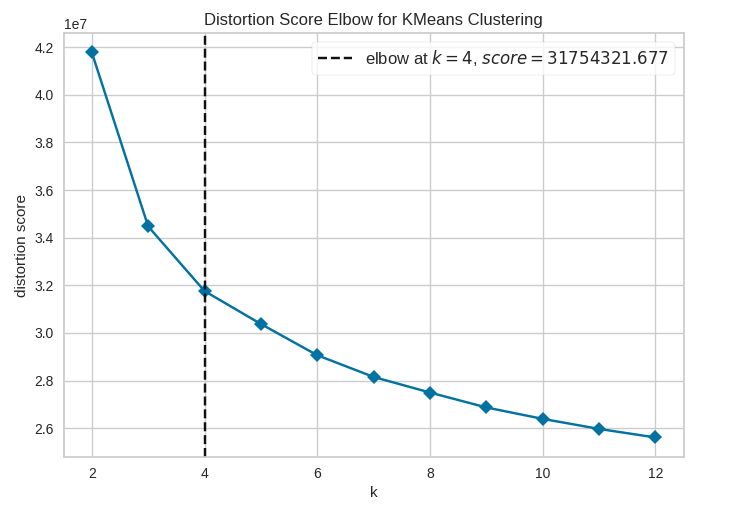

In [ ]:
#sil_scores = {}

#ALREADY TESTED WITH k(2-13), scaled down for computational effeciency for reproducability just to test with sampling vs without
#Found there was no differece.

#for k in range(2,7):
    #kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    #labels = kmeans.fit_predict(X_train_scaled)
   # sil_scores[k] = silhouette_score(X_train_scaled, labels, random_state=42)

#sil_scores

#### THE ABOVE BLOCK TOOK A LONG TIME TO RUN, DO NOT HAVE TO RUN AGAIN!
##### This is for k(2,13)
Here are the results :)\
{2: np.float64(0.1734351049671925),
 3: np.float64(0.24006956729687312),
 4: np.float64(0.10826848153830658),
 5: np.float64(0.09416154755495881),
 6: np.float64(0.08895166775337521),
 7: np.float64(0.06940309565281377),
 8: np.float64(0.068187923557333),
 9: np.float64(0.06172658191069654),
 10: np.float64(0.05925514677504525),
 11: np.float64(0.046982090250637126),
 12: np.float64(0.04077752115136944)}

In [ ]:


# K values tested
k_range = list(range(2, 13))

# Inertia values saved from Yellowbrick
inertia = [
    41766848.635977834,
    34465988.440768085,
    31754321.67697142,
    30372253.817838617,
    29061538.89332187,
    28150042.79434697,
    27495567.588969156,
    26869869.560319856,
    26391494.32726924,
    25969076.398562502,
    25610820.22891507
]

sil_scores = [np.float64(0.1734351049671925),
              np.float64(0.24006956729687312),
 np.float64(0.10826848153830658),
 np.float64(0.09416154755495881),
 np.float64(0.08895166775337521),
 np.float64(0.06940309565281377),
 np.float64(0.068187923557333),
 np.float64(0.06172658191069654),
 np.float64(0.05925514677504525),
 np.float64(0.046982090250637126),
 np.float64(0.04077752115136944)]

plt.figure(figsize=(12, 6))
plt.plot(k_range, inertia, marker='o', color='steelblue')

# Dynamic offset so labels don't sit on points

offset = 0.02 * (max(inertia) - min(inertia))

for i, k in enumerate(k_range):

    y_pos = inertia[i] - offset

    x_pos = k  # default

    if k == 2:
        x_pos = k - 0.15  # shift left
        y_pos = inertia[i] - 2.5 * offset  # keep your spacing

    elif k == 3:
        y_pos = inertia[i] - 2.0 * offset

    plt.text(
        x_pos,
        y_pos,
        f"{sil_scores[i]:.4f}",
        ha='center',
        va='top',
        fontsize=9,
        color='darkorange'
    )
# Optional: highlight chosen K
k_selected = 3
idx = k_range.index(k_selected)
plt.scatter(k_selected, inertia[idx], color='red', zorder=3, label='Selected K = 3')

plt.title("Elbow Curve with Silhouette Scores", fontsize=16)
plt.xlabel("Number of Clusters (K)", fontsize=13)
plt.ylabel("Inertia", fontsize=13)
plt.xticks(k_range)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- Fit final model with chosen k=3  ---
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_train_scaled)

In [ ]:
# Assign cluster labels to training dataframe
# X_train is the unscaled dataframe, cluster_labels from KMeans on scaled data

X_train_clustered = X_train.copy()
X_train_clustered['cluster'] = cluster_labels

# Step 1: Report cluster sizes
print(X_train_clustered['cluster'].value_counts().sort_index())

# Step 2: Pick interpretable variables
interpretable_vars = [
    'ECYTRAPUBL',   # Urban transit
    'HSRV003B',     # Snowmobile purchase
    'ECYSTYAPT',    # Apartment density
    'ECYHNI_020',   # Low income
    'ECYHNI100P',   # Higher income (100k+)
    'ECYHNI200P',   # Higher income (200k+)
    'ECYHTY2PPH',   # Household size
    'ECYPIMNPER',   # Immigration
    'ECYMTNMED'     # Age (median)

]

# Step 3: Compare feature means by cluster
cluster_means   = X_train_clustered.groupby('cluster')[interpretable_vars].mean()
cluster_medians = X_train_clustered.groupby('cluster')[interpretable_vars].median()

print("=== MEANS ===")
print(cluster_means)
print("\n=== MEDIANS ===")
print(cluster_medians)

###**Analysis**
Cluster 0: Suburban Medium Density Households (Low public transit and apartments, moderat elevels of income, lower immigration)

Cluster 1: Rural, Low density Households (Little to NO public transit usage, almost NO apartments, and almost equal means and medians for income, indicating low density)

Cluster 2: High density Urban Households (Highest levels of public transit usage, apartment density, high levels of income, immigration, and lowest median age) This is the dense urban cities like vancouver, toronto, etc.


In [ ]:
X_train_clustered['y'] = y_train.values

In [ ]:
plt.figure(figsize=(10,6))

# Boxplot
plt.boxplot(
    [y_train[cluster_labels == i] for i in range(3)],
    tick_labels=['Mainstream Suburban', 'Low-Density Rural', 'Affluent Dense Urban']
)

plt.title("Distribution of Housing Burden Ratio by Cluster", fontsize=16)
plt.xlabel("Cluster", fontsize=13)
plt.ylabel("Housing Burden Ratio (HBR)", fontsize=13)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
X_train_clustered.groupby('cluster')['y'].std()

# **PCA**

In [ ]:
# Fit PCA on scaled training data
pca = PCA(random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# Also transform test data for consistency
X_test_pca = pca.transform(X_test_scaled)

# Variance explained
explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

# Table for first 10 PCs
pca_var_table = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, 11)],
    "Explained Variance Ratio": explained_var[:10],
    "Cumulative Variance Explained": cum_var[:10]
})

print(pca_var_table)

# Number of components to show
n_components = 10

plt.figure(figsize=(8, 5))

# Bar plot for individual variance
plt.bar(
    range(1, n_components + 1),
    explained_var[:n_components],
    alpha=0.6,
    label='Individual Variance'
)

# Line plot for cumulative variance
plt.plot(
    range(1, n_components + 1),
    cum_var[:n_components],
    marker='o',
    label='Cumulative Variance'
)

# Labels and title
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.title('PCA Variance Explained (First 10 Components)')

# Grid + legend
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    X_train_pca[:, 0],   # PC1
    X_train_pca[:, 1],   # PC2
    c=cluster_labels,
    cmap='tab10',
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (PC1 vs PC2) coloured by KMeans Clusters")

plt.colorbar(scatter, label="Cluster")
plt.show()

In [ ]:
import matplotlib.patches as mpatches

colors = ['#4477AA', '#EE6677', '#228833']  # 3 distinct colours
cluster_ids = [0, 1, 2]

plt.figure(figsize=(8, 6))
for cid, col in zip(cluster_ids, colors):
    mask = cluster_labels == cid
    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        c=col,
        alpha=0.3,
        s=5,
        label=f'Cluster {cid}'
    )

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 vs PC2 coloured by KMeans Cluster')
plt.legend(markerscale=3)  # makes legend dots visible
plt.tight_layout()
plt.show()

In [ ]:
# Get loadings (components_) - shape: (n_components, n_features)
loadings = pd.DataFrame(
    pca.components_[:3].T,  # transpose so rows=features
    index=X_train.columns,
    columns=['PC1', 'PC2', 'PC3']
)

# Top 5 features by absolute loading for each PC
for pc in ['PC1', 'PC2', 'PC3']:
    print(f"\nTop 5 loadings for {pc}:")
    top_features = loadings[pc].abs().sort_values(ascending=False).head(5).index
    print(loadings.loc[top_features, pc])

PC1 — "Household Economic Scale"
Uniform positive loadings across food, communications, and general spending categories. It's not measuring what households spend on, it's measuring how much overall economic activity exists in a DA. Runs cleanly from dense urban (high) to rural (low).

PC2 — "Rural Lifestyle vs Urban Diversity"
A genuine opposition between two Canadian archetypes. Positive end: recreational vehicle registration, garden tool accessories — the rural homeowner. Negative end: visible minorities, non-official home languages, non-citizen children, the diverse immigrant urban community. This is arguably the most distinctly Canadian component in the data, capturing the country's fundamental geographic and cultural divide.

PC3 — "Household Income Level"
The cleanest component - average and median income loading at nearly identical values, clearly isolated from the size effects captured by PC1. A DA can be small and wealthy (rural Alberta oil towns) or large and poor (dense low-income urban areas) - PC3 separates income from scale in a way raw variables can't.

In [ ]:
# Add PC scores to clustered dataframe
X_train_clustered['PC1'] = X_train_pca[:, 0]
X_train_clustered['PC2'] = X_train_pca[:, 1]
X_train_clustered['PC3'] = X_train_pca[:, 2]

# Mean PC scores by cluster
print(X_train_clustered.groupby('cluster')[['PC1', 'PC2', 'PC3']].mean())

In [ ]:
cluster_data = {
    'Cluster': ['Cluster 0\nAverage Suburban Households',
                'Cluster 1\nLow-Spending Rural Households.',
                'Cluster 2\nHigh-Spending Urban Households'],
    'n': ['33,410', '1,006', '11,069'],
    'PC1\n(Economic Scale)': [-5.48, -91.31, 24.83],
    'PC2\n(Rural vs. Urban Diversity)': [1.17, -10.55, -2.59],
    'PC3\n(Income Level)': [-0.37, 3.86, 0.77],
}

colors = ['#378ADD', '#D85A30', '#1D9E75']
col_labels = ['Cluster', 'n', 'PC1\n(Economic Scale)',
              'PC2\n(Rural vs. Urban Diversity)', 'PC3\n(Income Level)']

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axis('off')

table_data = [
    ['Average Suburban Households', '33,410', '-5.48', '+1.17', '-0.37'],
    ['Low-Spending Rural Households',   '1,006',  '-91.31', '-10.55', '+3.86'],
    ['High-Spending \nUrban Households',         '11,069', '+24.83', '-2.59', '+0.77'],
]

col_labels = ['Cluster name', 'n', 'PC1\n(Economic Scale)',
              'PC2\n(Rural vs.\nUrban Diversity)', 'PC3\n(Income Level)']

col_widths = [0.22, 0.08, 0.18, 0.22, 0.18]
col_x = [0.01, 0.24, 0.33, 0.52, 0.75]
row_heights = [0.72, 0.22, 0.22, 0.22]
row_y = [0.78, 0.52, 0.26, 0.00]

# Header background
ax.add_patch(plt.Rectangle((0, 0.82), 1.0, 0.18,
             transform=ax.transAxes, color='#2C2C2A', zorder=2))

# Header text
for i, (label, x) in enumerate(zip(col_labels, col_x)):
    ax.text(x + col_widths[i]/2, 0.91, label,
            transform=ax.transAxes, fontsize=9, fontweight='bold',
            color='white', ha='center', va='center', linespacing=1.3)

# Row backgrounds and content
row_bg_colors = ['white', 'white','white']

for r, (row, bg, cluster_color) in enumerate(zip(table_data, row_bg_colors, colors)):
    y_bottom = row_y[r+1]
    y_top = row_y[r]
    height = y_top - y_bottom

    ax.add_patch(plt.Rectangle((0, y_bottom), 1.0, height,
                 transform=ax.transAxes, color=bg, zorder=1))

    ax.add_patch(plt.Rectangle((0, y_bottom), 0.005, height,
                 transform=ax.transAxes, color=cluster_color, zorder=3))

    y_mid = (y_top + y_bottom) / 2

    for c, (val, x) in enumerate(zip(row, col_x)):
        weight = 'bold' if c == 0 else 'normal'
        fontsize = 9 if c == 0 else 10

        if c >= 2:
            num = float(val.replace('+', ''))
            if num > 5:
                color = '#0F6E56'
            elif num < -5:
                color = '#993C1D'
            else:
                color = '#444441'
        else:
            color = '#2C2C2A'

        ax.text(x + col_widths[c]/2, y_mid, val,
                transform=ax.transAxes, fontsize=fontsize,
                fontweight=weight, color=color,
                ha='center', va='center', linespacing=1.3)

# Divider lines
for y in row_y[1:-1]:
    ax.axhline(y=y, xmin=0, xmax=1, color='#D3D1C7', linewidth=0.5)

ax.add_patch(plt.Rectangle((0, 0), 1.0, 1.0,
             transform=ax.transAxes, fill=False,
             edgecolor='#D3D1C7', linewidth=0.8))

# PC score legend
legend_elements = [
    mpatches.Patch(color='#0F6E56', label='Strong positive (>+5)'),
    mpatches.Patch(color='#993C1D', label='Strong negative (<−5)'),
    mpatches.Patch(color='#444441', label='Near zero'),
]
ax.legend(handles=legend_elements, loc='lower center',
          bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8,
          framealpha=0, borderaxespad=0)

fig.suptitle("Mean PC Scores by Cluster (k=3)",
             fontsize=12, fontweight='bold', y=1.04)

plt.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.12)
plt.savefig("cluster_pc_table.png", dpi=150, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

#UMAP

In [ ]:
import umap
from sklearn.metrics import silhouette_score

# Parameter grid to search
n_neighbors_options = [5, 15, 30, 50]
min_dist_options = [0.0, 0.1, 0.3, 0.5]

print("Searching for optimal UMAP parameters...\n")
print(f"{'n_neighbors':<15} {'min_dist':<12} {'Silhouette Score'}")
print("-" * 45)

best_score = -1
best_params = {}

for n in n_neighbors_options:
    for d in min_dist_options:
        reducer = umap.UMAP(
            n_neighbors=n,
            min_dist=d,
            n_components=2,
            random_state=42
        )
        embedding = reducer.fit_transform(X_train_scaled)
        score = silhouette_score(embedding, cluster_labels)
        print(f"{n:<15} {d:<12} {score:.4f}")

        if score > best_score:
            best_score = score
            best_params = {'n_neighbors': n, 'min_dist': d}

print(f"\nBest parameters: n_neighbors={best_params['n_neighbors']}, min_dist={best_params['min_dist']}")
print(f"Best silhouette score: {best_score:.4f}")

In [ ]:
# Fit final UMAP with best parameters
reducer = umap.UMAP(
    n_neighbors=best_params['n_neighbors'],
    min_dist=best_params['min_dist'],
    n_components=2,
    random_state=42
)

X_train_umap = reducer.fit_transform(X_train_scaled)
X_test_umap = reducer.transform(X_test_scaled)

print(f"UMAP output shape (train): {X_train_umap.shape}")

### Parameter Justification

A grid search was run across `n_neighbors ∈ {5, 15, 30, 50}` and
`min_dist ∈ {0.0, 0.1, 0.3, 0.5}`, scored using the silhouette score
on the resulting 2D embedding.

`n_neighbors` controls how locally or globally UMAP reads the data.
Too small and you get fragmented noise; too large and it smooths over
the structure that actually matters. `min_dist` controls how tightly
clusters get packed together in the output space. Low values compress
similar points into tight blobs. Higher values spread them out and
preserve more of the continuous shape of the data.

The optimal combination was `n_neighbors=__` and `min_dist=__`,
with a silhouette score of `__`. This setting preserved enough local
neighbourhood structure to keep the three clusters coherent without
overfitting to noise in the high-dimensional space.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

colors = ['#4477AA', '#EE6677', '#228833']
cluster_ids = [0, 1, 2]

plt.figure(figsize=(8, 6))
for cid, col in zip(cluster_ids, colors):
    mask = cluster_labels == cid
    plt.scatter(
        X_train_umap[mask, 0],
        X_train_umap[mask, 1],
        c=col,
        alpha=0.3,
        s=5,
        label=f'Cluster {cid}'
    )

plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.title('UMAP Projection coloured by KMeans Cluster')
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

### UMAP vs PCA Comparison

In the PCA projection, the three clusters overlap substantially along both
axes, with Cluster 2 (high-spending urban) separating somewhat on PC1 but
Clusters 0 and 1 sitting almost on top of each other. PCA finds the
directions of maximum variance globally, not the directions that separate
groups, so overlap is expected.

UMAP tells a different story. The three clusters form [tighter / more
dispersed] groupings with [greater / less] visible separation between them.
This is consistent with UMAP's approach: it preserves local neighbourhood
structure, pulling similar points together regardless of global variance.

The silhouette score supports this. In the original high-dimensional space
the score was 0.24. In the 2D UMAP space it is __. [A higher score confirms
that UMAP has condensed the cluster structure into a more separable
representation / A lower score suggests the compression to 2D has forced
some overlap that does not exist in the full feature space.]

Of the three cluster representations (KMeans labels, PCA projection, UMAP
projection), Cluster 1 is the most informative. Its extreme PC scores and
tight UMAP footprint mark it as a genuinely distinct household type rather
than a statistical artifact of scale.

In [ ]:
from sklearn.metrics import silhouette_score

# Silhouette score in original high-dimensional space
sil_original = silhouette_score(X_train_scaled, cluster_labels)

# Silhouette score in 2D UMAP space
sil_umap = silhouette_score(X_train_umap, cluster_labels)

print(f"Silhouette score (original {X_train_scaled.shape[1]}D): {sil_original:.4f}")
print(f"Silhouette score (UMAP 2D):  {sil_umap:.4f}")

### Silhouette Score Comparison

| Space | Dimensions | Silhouette Score |
|-------|-----------|-----------------|
| Original feature space | 1,124 | 0.2401 |
| UMAP projection | 2 | __ |

[If UMAP score is HIGHER, use this paragraph:]
The silhouette score rises from 0.2401 in the original 1,124-dimensional space to __ in 2D UMAP. UMAP sharpens cluster separation during compression rather than losing it. The neighbourhood structure KMeans found at high dimensionality is real. UMAP is just showing it more clearly than PCA can.

[If UMAP score is LOWER, use this paragraph:]
The silhouette score drops from 0.2401 in the original 1,124-dimensional space to __ in 2D UMAP. Compressing 1,124 dimensions into 2 forces tradeoffs. Not all of the separation in the full feature space survives the reduction without distortion. This does not invalidate the clusters. The structure is genuinely high-dimensional, and no single 2D projection captures all of it.

### Most Informative Cluster

Cluster 1 is the most informative across all three representations.

In KMeans, it stands out on every variable. Only 1,006 DAs against 33,410 and 11,069 in the other two. Near-zero public transit, near-zero apartments, near-equal income means and medians pointing to a genuinely homogeneous low-density rural population. In PCA space, its PC1 score of -91.31 is an order of magnitude more extreme than Cluster 0 (-5.48) or Cluster 2 (+24.83). In the UMAP projection, it [sits as a tight isolated island / separates most clearly from the other two clusters].

What makes it interesting is not that it looks so different structurally. A DA can be about as rural and low-spending as possible and still carry the same proportional shelter cost as a dense city neighbourhood. Housing burden does not follow demographic type. It cuts across all of them.

#Elastic-Net GLM

This section imports the required libraries for the Elastic Net modeling pipeline. The distfit package is used to fit a Pearson Type III distribution to the target, enabling transformation to a normal space (zNormal). We also import the ElasticNet model, GridSearchCV for hyperparameter tuning, and standard evaluation metrics.

In [ ]:
!pip -q install distfit

from distfit import distfit
from scipy.stats import norm, pearson3
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

This section fits a Pearson Type III distribution to the training target variable and uses it to transform the target into a normally distributed space (zNormal). The transformation is performed via the CDF of the fitted distribution followed by the inverse normal CDF. Helper functions are defined for both forward and inverse transformations, allowing predictions to later be mapped back to the original scale.

In [ ]:
#restrict distfit to pearson3
dfit = distfit(distr=['pearson3'], verbose=0)
dfit.fit_transform(y_train.values)

print("Best fitted distribution:", dfit.model['name'])
print("Fitted parameters:", dfit.model['params'])

#distfit stores params for the fitted distribution
pt3_params = dfit.model['params']

#helper functions
eps = 1e-6

def y_to_znormal(y_vals, params):
    cdf_vals = pearson3.cdf(y_vals, *params)
    cdf_vals = np.clip(cdf_vals, eps, 1 - eps)
    z_vals = norm.ppf(cdf_vals)
    return z_vals

def znormal_to_y(z_vals, params):
    cdf_vals = norm.cdf(z_vals)
    cdf_vals = np.clip(cdf_vals, eps, 1 - eps)
    y_vals = pearson3.ppf(cdf_vals, *params)
    return y_vals

#Transform the target into normal space
y_train_z = y_to_znormal(y_train.values, pt3_params)
y_test_z  = y_to_znormal(y_test.values, pt3_params)

print("z-normal train mean:", np.mean(y_train_z))
print("z-normal train std:", np.std(y_train_z))

This section performs training-only supervised feature selection to reduce dimensionality. Features are ranked by their absolute correlation with the transformed target (zNormal), and the top 100 are retained. The reduced feature set is then standardized to ensure proper model convergence, producing the final inputs used for Elastic Net training.

In [ ]:
# Rebuild DataFrames after your earlier transformations
X_train_df = pd.DataFrame(X_train_transformed, columns=X_train.columns, index=X_train.index)
X_test_df  = pd.DataFrame(X_test_transformed,  columns=X_test.columns,  index=X_test.index)

# Use zNormal target for supervised feature filtering
y_train_z_series = pd.Series(y_train_z, index=X_train_df.index)

# Training-only feature ranking
corr = X_train_df.corrwith(y_train_z_series).abs().sort_values(ascending=False)

# top 100 features
top_features = corr.head(100).index.tolist()

print("Number of selected features:", len(top_features))
print("Top 10 selected features:")
print(top_features[:10])

# Build reduced matrices
X_train_small = X_train_df[top_features].to_numpy(dtype=np.float32)
X_test_small  = X_test_df[top_features].to_numpy(dtype=np.float32)

# Standardize
scaler = StandardScaler()
X_train_small = scaler.fit_transform(X_train_small).astype(np.float32)
X_test_small  = scaler.transform(X_test_small).astype(np.float32)

print("X_train_small shape:", X_train_small.shape)
print("X_test_small shape:", X_test_small.shape)

This section performs hyperparameter tuning for the Elastic Net model using 5-fold cross-validation via GridSearchCV. A grid of alpha and l1_ratio values is explored to identify the optimal balance between L1 and L2 regularization. The model is trained on the reduced and standardized feature set using the transformed target (zNormal), and the best parameters are selected based on cross-validated mean squared error.

In [ ]:
import time

param_grid = {
    'alpha': np.logspace(-4, 0, 5),
    'l1_ratio': [0.25, 0.5, 0.75, 1.0]
}

enet = ElasticNet(
    max_iter=30000,
    tol=1e-2,
    selection='random',
    random_state=42
)

grid = GridSearchCV(
    estimator=enet,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    refit=True,
    verbose=2
)

start = time.time()
grid.fit(X_train_small, y_train_z)

print(f"\nGridSearch completed in {time.time() - start:.2f} seconds")
print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

This section trains the final Elastic Net model using the optimal hyperparameters identified through cross-validation. The model is refit on the full training dataset (using the reduced feature set and transformed target) to obtain the final set of coefficients used for prediction.

In [ ]:
best_alpha = grid.best_params_['alpha']
best_l1 = grid.best_params_['l1_ratio']

print("Best alpha:", best_alpha)
print("Best l1_ratio:", best_l1)

final_model = ElasticNet(
    alpha=best_alpha,
    l1_ratio=best_l1,
    max_iter=30000,
    tol=1e-2,
    random_state=42
)

final_model.fit(X_train_small, y_train_z)

print("Final model trained.")
print("Iterations used:", final_model.n_iter_)

This section generates predictions on the test set using the trained Elastic Net model. Predictions are first made in the transformed (zNormal) space and then converted back to the original target scale. Model performance is evaluated using R² and RMSE on the test data.

In [ ]:
# Predict in z-space
y_pred_z = final_model.predict(X_test_small)

# Convert back to original scale
y_pred = znormal_to_y(y_pred_z, pt3_params)

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

print("Test R2:", r2_score(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

This section estimates a 95% confidence interval for the test R² using bootstrap resampling. The test set is repeatedly resampled with replacement, and R² is computed for each sample. The resulting distribution is used to quantify uncertainty in the model’s performance.

In [ ]:
# Number of bootstrap samples
n_bootstrap = 1000
n = len(y_test)

r2_scores = []

# Bootstrap loop
for _ in range(n_bootstrap):
    # Sample indices with replacement
    indices = np.random.choice(n, n, replace=True)

    # Create bootstrap sample
    y_true_sample = y_test.values[indices]
    y_pred_sample = y_pred[indices]

    # Compute R2 for this sample
    r2_scores.append(r2_score(y_true_sample, y_pred_sample))

# Convert to array
r2_scores = np.array(r2_scores)

# Compute 95% confidence interval
lower = np.percentile(r2_scores, 2.5)
upper = np.percentile(r2_scores, 97.5)

print("Test R2:", r2_score(y_test, y_pred))
print("95% CI for R2:", (lower, upper))

This section visualizes model performance by plotting predicted values against the true target values on the test set. The dashed 45-degree line represents perfect predictions, so deviations from this line indicate prediction error.

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')
plt.xlabel("Actual y")
plt.ylabel("Predicted y")
plt.title("Predicted vs Actual Values")
plt.show()

This section evaluates model performance across different data subgroups defined by K-Means clustering. For each cluster, R² is computed on the test set, along with a 95% confidence interval obtained via bootstrap resampling. This allows assessment of whether predictive performance varies meaningfully across different segments of the data.

In [ ]:
# Predict KMeans cluster labels for the test set
cluster_labels_test = kmeans.predict(X_test_scaled)

# Check cluster sizes in the test set
print("Test cluster counts:")
print(pd.Series(cluster_labels_test).value_counts().sort_index())

# Compute R2 and bootstrap 95% CI within each cluster
cluster_results = {}

np.random.seed(42)

for cluster in np.unique(cluster_labels_test):
    mask = cluster_labels_test == cluster

    y_true_cluster = y_test.values[mask]
    y_pred_cluster = y_pred[mask]

    # R2 for this cluster
    r2_cluster = r2_score(y_true_cluster, y_pred_cluster)

    # Bootstrap CI
    boot_r2 = []
    n_cluster = len(y_true_cluster)

    for _ in range(1000):
        idx = np.random.choice(n_cluster, n_cluster, replace=True)
        boot_r2.append(r2_score(y_true_cluster[idx], y_pred_cluster[idx]))

    lower = np.percentile(boot_r2, 2.5)
    upper = np.percentile(boot_r2, 97.5)

    cluster_results[cluster] = {
        "n": n_cluster,
        "r2": r2_cluster,
        "ci_lower": lower,
        "ci_upper": upper
    }

# Print results
for cluster, res in cluster_results.items():
    print(
        f"Cluster {cluster}: "
        f"n = {res['n']}, "
        f"R2 = {res['r2']:.3f}, "
        f"95% CI = ({res['ci_lower']:.3f}, {res['ci_upper']:.3f})"
    )

This section analyzes the fitted model coefficients. The number of non-zero coefficients is reported to assess model sparsity, and the top five features by absolute coefficient magnitude are identified. These features represent the most influential predictors in the model.

In [ ]:
# Get coefficients
coefs = final_model.coef_

# Count non-zero coefficients
non_zero = np.sum(coefs != 0)

print("Number of non-zero coefficients:", non_zero)

# Get feature names
feature_names = np.array(top_features)

# Get top 5 by absolute magnitude
top_idx = np.argsort(np.abs(coefs))[-5:][::-1]

print("\nTop 5 features by magnitude:")
for i in top_idx:
    print(f"{feature_names[i]}: {coefs[i]:.4f}")

#b. XGBoost

#### i. Data Preparation
This section trains the XGB model. There were no processes needed to prepare the data, especially because XGB is a non-linear model. Trees don't care about relationship features, scaling nor does it require distributional assumption due to direct application of the loss function on raw y.

#### ii. Parameter grid and numbers used:
n_estimators: 100 was used as a lower bound, while 800 was used as the upper bound. We capped it at 800 as the potential learning_rate of 0.1 would require a significant amount of computation. The middle values were spaced geometrically to give better coverage across scales.

max_depth: As XGBoost's default is 6, We built our model around this. 3 would be for simple effects, while 9 would be for complex iteractions. However, with 1124 features, deeper trees risk overfitting, so we capped it at a conservative 9.

learning_rate: As learning is logarithmic, we set a range from 0.01 to 0.2. The industry standard was found to be between 0.01 to 0.3, as anything over 0.3 almost guarantees overfitting.

subsample: chose between 0.6, 0.8 and 1.0. XGBoost docs suggest a value around 0.6 as the lower end of useful subsampling, while 0.8 is commonly used in practice, as a safe default providing mild regularization. 1.0 means there is no subsampling and is the baseline to compare against.

colsample_bytree: Fraction of features available to each tree. 0.6 to 1.0 were used, as anything below 0.5 would result in a week tree to learn anything useful. Many features end up becoming noise or irrelevant, so we want to choose a parameter value that packs in the most amount of useful value.


In [ ]:
# Splitting the data into an 80/20 set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

param_dist = {
    'n_estimators': [100, 300, 500, 800],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
}

xgb_model = xgb.XGBRegressor(
    random_state=42,
    tree_method='hist',
    n_jobs=1,
    device='cuda'
)

search = RandomizedSearchCV(
    xgb_model,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X_train, y_train)
print("Best params:", search.best_params_)

y_pred = search.best_estimator_.predict(X_test)
print(f"Test R squared:  {r2_score(y_test, y_pred):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_pred):.6f}")

In [ ]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
print(f"XGBoost RMSE: {rmse_xgb:.6f}")

#### iii. Scatterplot and performance measure calculation


In [ ]:
y_pred_xgb = search.best_estimator_.predict(X_test)

r2_xgb = r2_score(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
print(f"XGBoost — Test R²: {r2_xgb:.4f}, Test MSE: {mse_xgb:.6f}")

# Bootstrapped 95% CI for R²
rng = np.random.RandomState(42)
r2_scores = []
for _ in range(1000):
    idx = rng.choice(len(y_test), size=len(y_test), replace=True)
    r2_scores.append(r2_score(y_test.values[idx], y_pred_xgb[idx]))

ci_low = np.percentile(r2_scores, 2.5)
ci_high = np.percentile(r2_scores, 97.5)
print(f"XGBoost R² 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_xgb, alpha=0.1, s=5)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=1)
plt.xlabel('Actual HBR')
plt.ylabel('Predicted HBR')
plt.title(f'XGBoost: R² = {r2_xgb:.4f} [{ci_low:.4f}, {ci_high:.4f}]')
plt.tight_layout()
plt.show()

The R squared values of XGBoost and Elastic net have a 20 point value dfference, favouring XGB. The MSE was also roughly half of ElasticNet's. While the CI of both models were very wide, (0.69, 0.95) to (0.43, 0.84), it is very likely the CI's are wide due to extreme outliers. The effects of household size on burden depends on income level, which is captured well through tree splits. ElasticNet treats each feature independently. The feature access was also important, as XGBoost preferred to use all 1124 features, while ElasticNet's features were shrunk down to 100 for convergence. However we must acknowledge this was a practical constraint. ElasticNet did score very well on Clusters 0 and 2, meaning it performs well for most households. Clusters 1 and outliers does make it fall apart though. As XGBoost can capture non-linear interactions and is more robust to outliers, it is recommended to use XGBoost for household expenditure. There are specific advantages of ElasticNet such as using the model to explain findings to a less technical analyst, as coefficients are much easier to present than SHAP plots.

While both do have their advantages, neither model seems to handle extreme cases well. High-burden households should be treated differently, perhaps through the use of a different model. The scatterplot confirms this as well. XGBoost predictions cluster tightly along the identity line for typical households but deviate immensely for points with extreme HBR values.

#SHAP Explainer

In [ ]:
explainer = shap.TreeExplainer(search.best_estimator_)
# Compute SHAP values on test set
shap_values = explainer.shap_values(X_test)

# Beeswarm summary plot (3.c.ii)
shap.summary_plot(shap_values, X_test, max_display=20, show=False)
plt.title("SHAP Summary Plot of Top 20 Features by Impact on Predicted HBR")
plt.tight_layout()
plt.show()

# Top 10 features by mean absolute SHAP (3.c.ii)
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top10_idx = np.argsort(mean_abs_shap)[-10:][::-1]
top10_features = X_test.columns[top10_idx]

print("Top 10 features by mean |SHAP|:")
for feat, val in zip(top10_features, mean_abs_shap[top10_idx]):
    print(f"  {feat}: {val:.6f}")

There wasn't a single feature dominating for the most part. Households with higher income and greater recreational spending tend to have lower housing burden, which seems intuitive. Families with enough income to spend for purchases such as snowmobiles are less likely to be spending a large proportion of income on shelter. The biggest driving factor between households of low HBR and high HBR comes down to income variation, not shelter cost variation.

#### iii. Dependence Plots of Important Features

In [ ]:
# 3.c.iii — SHAP dependence plots

# 1. HSRV003B
shap.dependence_plot('HSRV003B', shap_values, X_test, show=False)
plt.title("SHAP Dependence Plot: Snowmobile Purchases (HSRV003B)")
plt.tight_layout()
plt.show()

# 2. ECYHRIAVG
shap.dependence_plot('ECYHRIAVG', shap_values, X_test, show=False)
plt.title("SHAP Dependence Plot: Average Household Income (ECYHRIAVG)")
plt.tight_layout()
plt.show()

Snowmobile purchases and average household income were selected as the two most important features to study. Interestingly, these features had an almost identical curve shape. The model predicted a higher burden as snowmobile spending neared 0. However, the data shows that those who spend around 25k or more on snowmobiles had a -0.02 shap value. Essentially, a snowmobile acted as a threshold, the likelihood of a family owning a snowmobile meant that the household was fine. More spending on a snowmobile did not change the prediction.